# 011 - Regularização do MLP com weight decay

## Objetivo

Partir do MLP de referência do 010 e variar apenas `weight_decay` do Adam: `0`, `0.0001` e `0.001`. A arquitetura, ReLU, 16 logits, CrossEntropyLoss sem pesos, learning rate, batch size, semente, épocas máximas e partições permanecem iguais. A validação interna escolhe a primeira época com melhor Macro F1 para cada valor; a validação fixa é usada uma vez apenas na avaliação final.

## Ambiente, dados e partições iguais às do 010

Reutilizamos a preparação comum e repetimos exatamente a divisão `test_size=0.2`, `random_state=42` e a validação interna estratificada de 15% (`random_state=42`) da parcela de treino. O pré-processador é ajustado uma vez apenas em `X_inner_train`; todas as variantes utilizam a mesma matriz transformada, e a validação fixa permanece reservada até a escolha do weight decay e da época.

In [1]:
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, TensorDataset

candidate_roots = [Path.cwd(), *Path.cwd().resolve().parents]
repo_root = next(
    (p for p in candidate_roots if (p / 'notebooks').is_dir() and (p / 'src' / 'preparar_dados.py').is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError('Não foi possível localizar a raiz do projeto com notebooks/ e src/preparar_dados.py.')
sys.path.insert(0, str(repo_root))
from src.preparar_dados import build_preprocessor, make_stratified_split, preparar_dados

train_path = repo_root / 'notebooks' / 'dataset_train.csv'
test_path = repo_root / 'notebooks' / 'dataset_test_X.csv'
if not train_path.is_file() or not test_path.is_file():
    raise FileNotFoundError(f'CSV de treino/teste não encontrados em {repo_root / "notebooks"}')

print(f'Python: {sys.version}')
print(f'PyTorch: {torch.__version__}; scikit-learn: {sklearn.__version__}')
print('Dispositivo: CPU')

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
prepared = preparar_dados(train_df, test_df)
X_train, X_val, y_train, y_val = make_stratified_split(
    prepared['X_train'], prepared['y_train'], test_size=0.2, random_state=42
)
assert len(X_train) == 8769 and len(X_val) == 2193
assert X_train.columns.equals(X_val.columns)

X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42, stratify=y_train
)
assert len(X_inner_train) == 7453 and len(X_inner_val) == 1316
print(f'Treino da experiência: {X_train.shape}; validação fixa: {X_val.shape}')
print(f'Treino interno: {X_inner_train.shape}; validação interna: {X_inner_val.shape}')

Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 11:23:37) [Clang 14.0.6 ]
PyTorch: 2.15.0; scikit-learn: 1.6.1
Dispositivo: CPU


Treino da experiência: (8769, 236); validação fixa: (2193, 236)
Treino interno: (7453, 236); validação interna: (1316, 236)


## Pré-processamento e MLP fixos

O pré-processador aprende imputação, categorias e normalização apenas no treino interno. A matriz one-hot esparsa é convertida para `float32` denso para PyTorch. As três variantes partilham as mesmas matrizes, arquitetura 64 → 32 → 16, CrossEntropyLoss sem pesos, Adam com `lr=0.001`, `batch_size=128`, semente 42 e limite de 100 épocas. A única diferença no otimizador será `weight_decay`.

In [2]:
SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 100
LEARNING_RATE = 0.001
NUM_CLASSES = 16
WEIGHT_DECAYS = [0.0, 0.0001, 0.001]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

def to_dense_float32(matrix):
    if hasattr(matrix, 'toarray'):
        matrix = matrix.toarray()
    return np.asarray(matrix, dtype=np.float32)

inner_preprocessor = build_preprocessor(X_inner_train, normalize_numeric=True)
X_inner_train_array = to_dense_float32(inner_preprocessor.transform(X_inner_train))
X_inner_val_array = to_dense_float32(inner_preprocessor.transform(X_inner_val))
y_inner_train_array = y_inner_train.to_numpy(dtype=np.int64)
y_inner_val_array = y_inner_val.to_numpy(dtype=np.int64)
input_size = X_inner_train_array.shape[1]
print(f'Características transformadas: {input_size}')
print(f'Memória matrizes densas: {(X_inner_train_array.nbytes + X_inner_val_array.nbytes) / 1024**2:.1f} MiB')

class AgeRangeMLP(torch.nn.Module):
    def __init__(self, input_features):
        super().__init__()
        self.layers = torch.nn.Sequential(
            torch.nn.Linear(input_features, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, NUM_CLASSES),
        )

    def forward(self, features):
        return self.layers(features)

def make_mlp(input_features, seed=SEED):
    torch.manual_seed(seed)
    return AgeRangeMLP(input_features).to('cpu')

def score_model(model, features, targets, criterion):
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(features))
        loss_value = criterion(logits, torch.from_numpy(targets)).item()
        predictions = logits.argmax(dim=1).cpu().numpy()
    macro_f1 = f1_score(
        targets, predictions, labels=list(range(NUM_CLASSES)), average='macro', zero_division=0
    )
    return float(loss_value), float(macro_f1)

criterion = torch.nn.CrossEntropyLoss()
print(AgeRangeMLP(input_size))

Características transformadas: 2324
Memória matrizes densas: 77.7 MiB
AgeRangeMLP(
  (layers): Sequential(
    (0): Linear(in_features=2324, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
  )
)


## Comparação de weight decay e curvas

Cada variante começa com os mesmos pesos iniciais e a mesma ordem determinística dos mini-batches. Por época registamos perda e Macro F1 do treino interno e da validação interna. A época escolhida é a primeira que atinge o maior Macro F1 interno; registamos também Macro F1 de treino nessa época, duração e todas as curvas.

,weight_decay,best_epoch,best_train_macro_f1,best_validation_macro_f1,train_loss_at_best_epoch,validation_loss_at_best_epoch,training_seconds
0,0.0000,18,0.736594,0.467805,0.716612,1.380989,31.847905
1,0.0001,18,0.730048,0.466559,0.744029,1.351942,34.110847
2,0.0010,24,0.669689,0.455504,0.822803,1.320639,28.914990


Weight decay selecionado: 0.0
Época selecionada: 18
Macro F1 interna: 0.4678


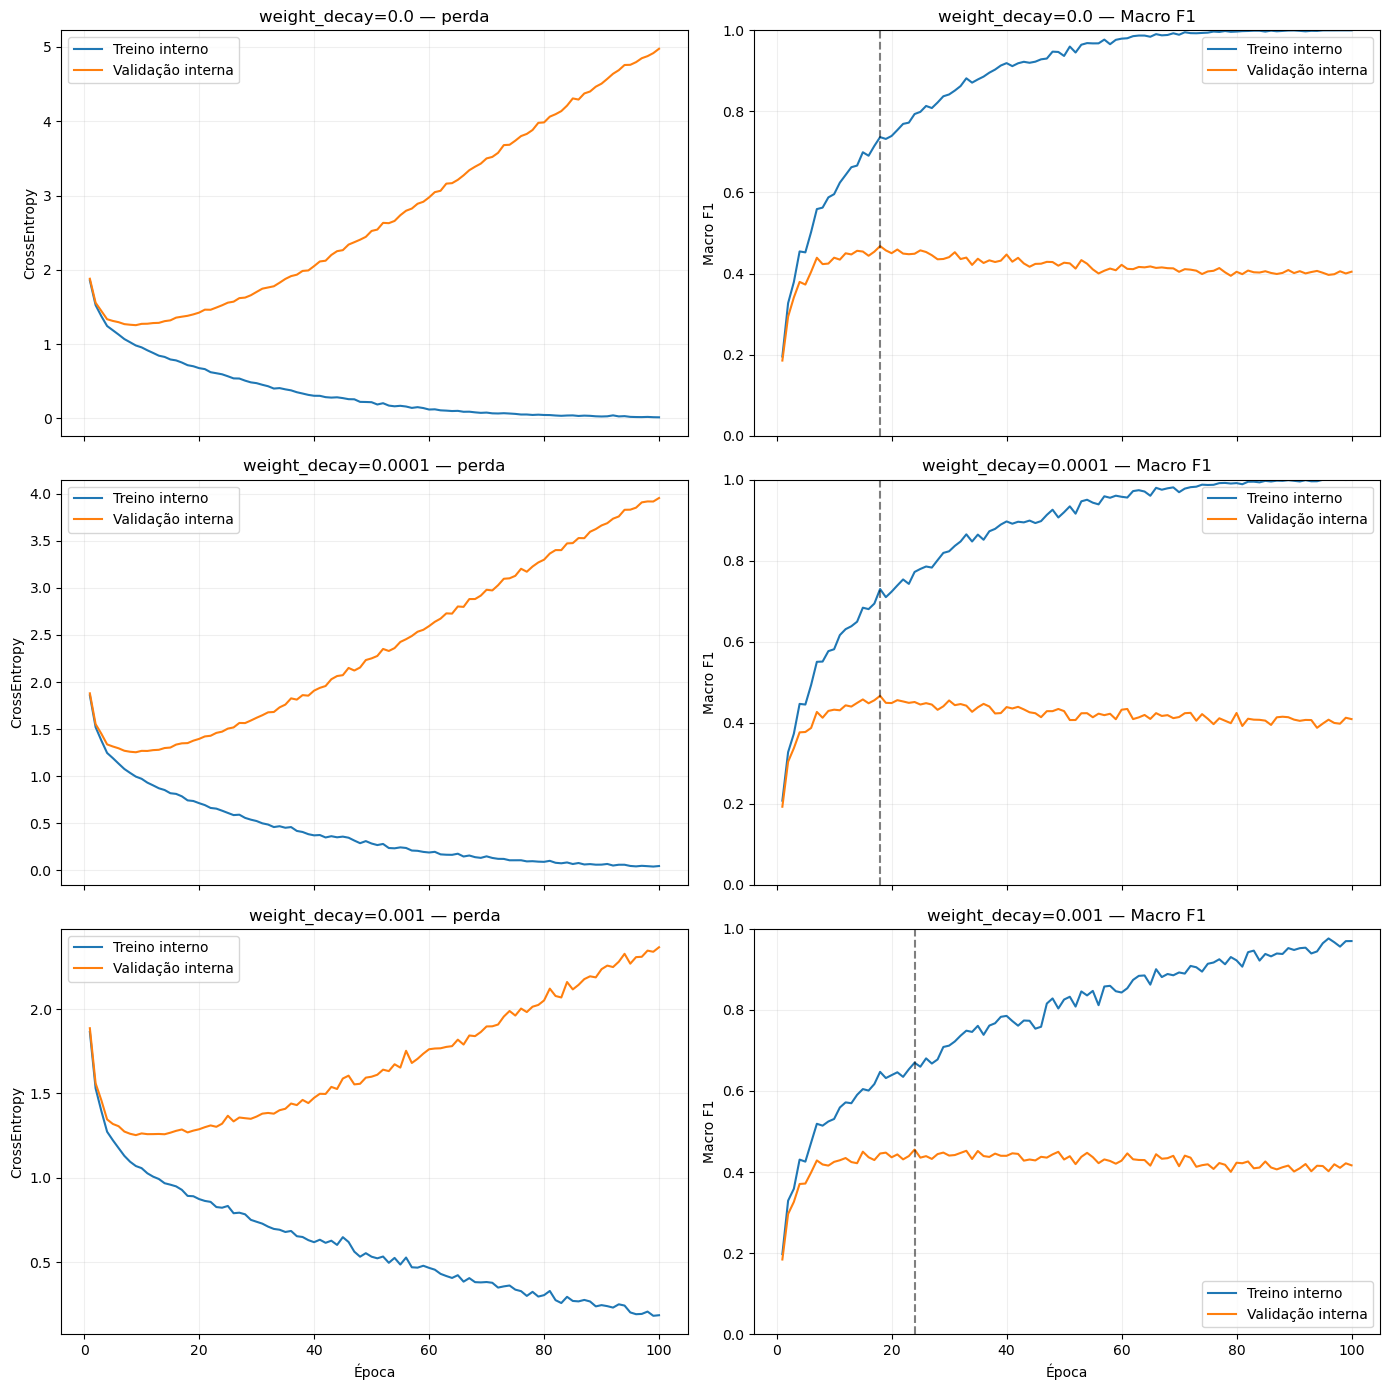

In [3]:
train_dataset = TensorDataset(
    torch.from_numpy(X_inner_train_array),
    torch.from_numpy(y_inner_train_array),
)
histories = {}
selection_rows = []

for weight_decay in WEIGHT_DECAYS:
    model = make_mlp(input_size, seed=SEED)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=weight_decay
    )
    generator = torch.Generator(device='cpu').manual_seed(SEED)
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
    )
    history = {
        'epoch': [],
        'train_loss': [],
        'validation_loss': [],
        'train_macro_f1': [],
        'validation_macro_f1': [],
    }
    start_time = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for batch_features, batch_targets in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits = model(batch_features)
            loss = criterion(logits, batch_targets)
            loss.backward()
            optimizer.step()
        train_loss, train_macro_f1 = score_model(
            model, X_inner_train_array, y_inner_train_array, criterion
        )
        val_loss, val_macro_f1 = score_model(
            model, X_inner_val_array, y_inner_val_array, criterion
        )
        history['epoch'].append(epoch)
        history['train_loss'].append(train_loss)
        history['validation_loss'].append(val_loss)
        history['train_macro_f1'].append(train_macro_f1)
        history['validation_macro_f1'].append(val_macro_f1)

    training_seconds = time.perf_counter() - start_time
    best_index = int(np.argmax(history['validation_macro_f1']))
    best_epoch = history['epoch'][best_index]
    histories[weight_decay] = history
    selection_rows.append({
        'weight_decay': weight_decay,
        'best_epoch': best_epoch,
        'best_train_macro_f1': history['train_macro_f1'][best_index],
        'best_validation_macro_f1': history['validation_macro_f1'][best_index],
        'train_loss_at_best_epoch': history['train_loss'][best_index],
        'validation_loss_at_best_epoch': history['validation_loss'][best_index],
        'training_seconds': training_seconds,
    })

selection_table = pd.DataFrame(selection_rows).sort_values(
    ['best_validation_macro_f1', 'weight_decay'], ascending=[False, True]
).reset_index(drop=True)
display(selection_table)
best_selection = selection_table.iloc[0]
selected_weight_decay = float(best_selection['weight_decay'])
selected_epoch = int(best_selection['best_epoch'])
print(f'Weight decay selecionado: {selected_weight_decay}')
print(f'Época selecionada: {selected_epoch}')
print(f'Macro F1 interna: {best_selection["best_validation_macro_f1"]:.4f}')

fig, axes = plt.subplots(3, 2, figsize=(14, 14), sharex=True)
for row_index, weight_decay in enumerate(WEIGHT_DECAYS):
    history = histories[weight_decay]
    axes[row_index, 0].plot(history['epoch'], history['train_loss'], label='Treino interno')
    axes[row_index, 0].plot(history['epoch'], history['validation_loss'], label='Validação interna')
    axes[row_index, 0].set_title(f'weight_decay={weight_decay} — perda')
    axes[row_index, 0].set_ylabel('CrossEntropy')
    axes[row_index, 0].grid(alpha=0.2)
    axes[row_index, 0].legend()

    axes[row_index, 1].plot(history['epoch'], history['train_macro_f1'], label='Treino interno')
    axes[row_index, 1].plot(history['epoch'], history['validation_macro_f1'], label='Validação interna')
    selected = selection_table.loc[selection_table['weight_decay'] == weight_decay].iloc[0]
    axes[row_index, 1].axvline(int(selected['best_epoch']), color='black', linestyle='--', alpha=0.5)
    axes[row_index, 1].set_title(f'weight_decay={weight_decay} — Macro F1')
    axes[row_index, 1].set_ylabel('Macro F1')
    axes[row_index, 1].set_ylim(0, 1)
    axes[row_index, 1].grid(alpha=0.2)
    axes[row_index, 1].legend()
axes[-1, 0].set_xlabel('Época')
axes[-1, 1].set_xlabel('Época')
plt.tight_layout()
plt.show()

## Rede nova nos 80% de treino e validação fixa

Com o weight decay e número de épocas selecionados internamente, ajustamos um pré-processador novo nos 80% completos e treinamos uma rede nova nessa parcela. Avaliamos uma única vez nos 20% fixos. Reportamos Macro F1, accuracy, F1 e recall para cada escalão e matriz de confusão; a classe 1 corresponde a 18–19 anos e será destacada face ao recall 3/34 do 010.

In [4]:
full_train_preprocessor = build_preprocessor(X_train, normalize_numeric=True)
X_train_array = to_dense_float32(full_train_preprocessor.transform(X_train))
X_val_array = to_dense_float32(full_train_preprocessor.transform(X_val))
y_train_array = y_train.to_numpy(dtype=np.int64)
y_val_array = y_val.to_numpy(dtype=np.int64)

final_model = make_mlp(X_train_array.shape[1], seed=SEED)
final_optimizer = torch.optim.Adam(
    final_model.parameters(), lr=LEARNING_RATE, weight_decay=selected_weight_decay
)
final_dataset = TensorDataset(torch.from_numpy(X_train_array), torch.from_numpy(y_train_array))
final_generator = torch.Generator(device='cpu').manual_seed(SEED)
final_loader = DataLoader(
    final_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=final_generator,
    num_workers=0,
)
for _ in range(selected_epoch):
    final_model.train()
    for batch_features, batch_targets in final_loader:
        final_optimizer.zero_grad(set_to_none=True)
        logits = final_model(batch_features)
        loss = criterion(logits, batch_targets)
        loss.backward()
        final_optimizer.step()

final_model.eval()
with torch.no_grad():
    validation_predictions = final_model(torch.from_numpy(X_val_array)).argmax(dim=1).cpu().numpy()
final_macro_f1 = f1_score(
    y_val_array, validation_predictions,
    labels=list(range(NUM_CLASSES)), average='macro', zero_division=0,
)
final_accuracy = accuracy_score(y_val_array, validation_predictions)
report = classification_report(
    y_val_array, validation_predictions,
    labels=list(range(NUM_CLASSES)), target_names=[str(i) for i in range(NUM_CLASSES)],
    output_dict=True, zero_division=0,
)
per_class_metrics = pd.DataFrame([
    {
        'AGE_RANGE': class_id,
        'precision': report[str(class_id)]['precision'],
        'recall': report[str(class_id)]['recall'],
        'f1': report[str(class_id)]['f1-score'],
        'support': int(report[str(class_id)]['support']),
    }
    for class_id in range(NUM_CLASSES)
])
print(f'Weight decay: {selected_weight_decay}; épocas: {selected_epoch}')
print(f'Macro F1 validação fixa: {final_macro_f1:.4f}')
print(f'Accuracy validação fixa: {final_accuracy:.4f}')
print(f'Recall classe 1 (18–19 anos): {report["1"]["recall"]:.4f} ({int(report["1"]["recall"] * report["1"]["support"])}/{int(report["1"]["support"])})')
display(per_class_metrics)
print(classification_report(
    y_val_array, validation_predictions,
    labels=list(range(NUM_CLASSES)), target_names=[str(i) for i in range(NUM_CLASSES)],
    zero_division=0,
))
confusion = confusion_matrix(y_val_array, validation_predictions, labels=list(range(NUM_CLASSES)))
display(pd.DataFrame(confusion, index=pd.Index(range(NUM_CLASSES), name='real'), columns=pd.Index(range(NUM_CLASSES), name='prevista')))

Weight decay: 0.0; épocas: 18
Macro F1 validação fixa: 0.3983
Accuracy validação fixa: 0.4195
Recall classe 1 (18–19 anos): 0.0882 (3/34)


,AGE_RANGE,precision,recall,f1,support
0,0,0.666667,0.731707,0.697674,41
1,1,0.428571,0.088235,0.146341,34
2,2,0.479592,0.587500,0.528090,80
3,3,0.344262,0.280000,0.308824,75
4,4,0.265306,0.288889,0.276596,90
5,5,0.309524,0.302326,0.305882,129
6,6,0.371429,0.302326,0.333333,172
7,7,0.419048,0.254335,0.316547,173
8,8,0.459459,0.751381,0.570231,181
9,9,0.641892,0.467980,0.541311,203


              precision    recall  f1-score   support

           0       0.67      0.73      0.70        41
           1       0.43      0.09      0.15        34
           2       0.48      0.59      0.53        80
           3       0.34      0.28      0.31        75
           4       0.27      0.29      0.28        90
           5       0.31      0.30      0.31       129
           6       0.37      0.30      0.33       172
           7       0.42      0.25      0.32       173
           8       0.46      0.75      0.57       181
           9       0.64      0.47      0.54       203
          10       0.51      0.63      0.56       213
          11       0.45      0.52      0.48       208
          12       0.35      0.20      0.26       200
          13       0.27      0.25      0.26       165
          14       0.30      0.56      0.39       130
          15       0.59      0.29      0.39        99

    accuracy                           0.42      2193
   macro avg       0.43   

prevista,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
real,,,,,,,,,,,,,,,,
0,30,3,7,0,1,0,0,0,0,0,0,0,0,0,0,0
1,9,3,22,0,0,0,0,0,0,0,0,0,0,0,0,0
2,5,0,47,8,8,8,1,0,3,0,0,0,0,0,0,0
3,1,1,11,21,24,5,6,2,4,0,0,0,0,0,0,0
4,0,0,5,19,26,19,10,2,9,0,0,0,0,0,0,0
5,0,0,2,10,25,39,29,7,17,0,0,0,0,0,0,0
6,0,0,2,3,9,39,52,23,44,0,0,0,0,0,0,0
7,0,0,0,0,4,12,31,44,82,0,0,0,0,0,0,0
8,0,0,2,0,1,4,11,27,136,0,0,0,0,0,0,0


## Comparação com 010 e 007

Comparamos Macro F1 na mesma validação fixa: MLP 010 (**0,3983**) e XGBoost 007 (**0,4491**). A classe 1 é a de 18–19 anos; no 010 o recall foi **3/34 = 0,0882**.

In [5]:
comparison = pd.DataFrame([
    {'experiencia': '011 - MLP com weight decay', 'macro_f1_validacao': final_macro_f1},
    {'experiencia': '010 - MLP referência', 'macro_f1_validacao': 0.3983},
    {'experiencia': '007 - XGBoost', 'macro_f1_validacao': 0.4491},
])
comparison['diferenca_vs_011'] = comparison['macro_f1_validacao'] - final_macro_f1
display(comparison)

,experiencia,macro_f1_validacao,diferenca_vs_011
0,011 - MLP com weight decay,0.398275,0.000000
1,010 - MLP referência,0.398300,0.000025
2,007 - XGBoost,0.449100,0.050825


## Conclusão e decisão
- Data: 10/11
- Pontuação Kaggle: 
- Conclusões: A ponderação aumentou o recall dos 18–19 anos de 3/34 para 25/34, mas reduziu o recall noutros escalões, incluindo 40–44 e 75–79 anos.

- A melhor configuração pela validação interna foi `weight_decay=0`, com Macro F1 **0,4678** na época **18** (F1 de treino **0,7366**). `weight_decay=0,0001` ficou praticamente igual (**0,4666**, época 18), enquanto `0,001` teve resultado inferior (**0,4555**, época 24). As curvas e as métricas de treino mostram uma diferença persistente entre treino e validação; a regularização testada não melhorou a Macro F1 interna.
Na validação fixa, a configuração selecionada obteve Macro F1 **0,3983** e accuracy **0,4195**, igualando o MLP 010, mas abaixo do XGBoost 007 (**0,4491**). O recall dos 18–19 anos continua baixo: **0,0882 (3/34)**.
- Melhorias: Comparar arquiteturas, começando por 64, 64 → 32 e 128 → 64, com a mesma divisão interna e a mesma perda ponderada.
